# Convection-diffusion equation in 2D

## Setting up the problem

We solve the two-dimensional convection-diffusion equation with Dirichlet boundary conditions, i.e.
$$\frac{\partial u}{\partial t} + \mathbf{v} \cdot \nabla u - D \nabla^2 u = f(x,y,t),\quad \text{for}\quad (x,y)\in (0,L_x) \times (0,L_y) =: \Omega \quad \text{and}\quad t > 0,$$
$$u(x,0,t) = u_{\text{bottom}},\quad u(x,L_y,t) = u_{\text{top}},\quad u(0,y,t) = u_{\text{left}},\quad u(L_x,y,t) = u_{\text{right}},$$
$$u(x,y,0) = g(x,y),$$
where:
-  $x,y$ are the spatial coordinates,
-  $t$ is the time,
-  $\mathbf{v}$ is the velocity field that the quantity is moving with,
-  $D$ is the diffusion coefficient,
-  $L_x, L_y$ are the width and length of the domain,
-  $u(x,y,t)$ is the variable of interest,
-  $f(x,y,t)$ is the source/sink term,
-  $u_{\text{bottom}}, u_{\text{top}}, u_{\text{left}}, u_{\text{right}}$ are the boundary values,
-  $g(x,y)$ is the initial profile.

To test the implementation, we use the analytical steady-state (so $\frac{\partial u}{\partial t} = 0$) solution $u(x,y) = \sin(\frac{m_x \pi}{L_x} x) \sin(\frac{m_y \pi}{L_y} y)$ with $m_x, m_y\in \mathbb{N}$.

In [1]:
using Mantis
using GLMakie

# Velocity field
v = [1.0, 1.0]

# Diffusion coefficient
D = 0.1

# Width and length of the domain
L_x = 1.0
L_y = 1.0

# Analytical steady-state solution
m_x = 2
m_y = 2
u_analytical_expression(x) = [@. sin(m_x*π/L_x * x[:, 1]) * sin(m_y*π/L_y * x[:, 2])]

# Source/sink term
f_expression(x) = [@. v[1] * m_x*π/L_x * cos(m_x*π/L_x * x[:, 1]) * sin(m_y*π/L_y * x[:, 2]) + 
                      v[2] * m_y*π/L_y * sin(m_x*π/L_x * x[:, 1]) * cos(m_y*π/L_y * x[:, 2]) + 
                      D * ((m_x*π/L_x)^2 + (m_y*π/L_y)^2) * sin(m_x*π/L_x * x[:, 1]) * sin(m_y*π/L_y * x[:, 2])]

# Boundary values
u_bottom = 0.0
u_top = 0.0
u_left = 0.0
u_right = 0.0

# Initial profile
g_expression(x) = [zeros(length(x[:, 1]))];

## Defining the finite element space

Now, we choose the number of elements to divide the domain into, and the polynomial degree and smoothness of the basis functions, to create a piecewise-polynomial function space $V_h$.

In [2]:
# Number of elements in each direction
num_elements_x = 10
num_elements_y = 10

# Polynomial degree of the basis functions in each direction
polynomial_degree_x = 3
polynomial_degree_y = 3

# Smoothness of the basis functions in each direction (-1 <= smoothness <= p-1)
smoothness_x = 2
smoothness_y = 2

# Create a piecewise-polynomial function space
geometry = Geometry.create_cartesian_box((0.0, 0.0), (L_x, L_y), (num_elements_x, num_elements_y))
V_h = FunctionSpaces.create_bspline_space((0.0, 0.0), (L_x, L_y), (num_elements_x, num_elements_y), (polynomial_degree_x, polynomial_degree_y), (smoothness_x, smoothness_y))

# Use this function space as a differential form
V⁰ = Forms.FormSpace(0, V_h, L"V^0")

# Use the expressions as form fields
u_analytical = Forms.AnalyticalFormField(0, u_analytical_expression, geometry, L"u_{\text{analytical}}")
f = Forms.AnalyticalFormField(0, f_expression, geometry, "f")
g = Forms.AnalyticalFormField(0, g_expression, geometry, "g");

## Deriving the weak form and assembling the system of ODEs

We define the trial and test space, respectively, as
$$S_h := \{v_h(x,y) \in V_h\ :\ v_h(x,0) = u_{\text{bottom}},\ v_h(x,L_y) = u_{\text{top}},\ v_h(0,y) = u_{\text{left}},\ v_h(L_x,y) = u_{\text{right}}\},$$
$$W_h := \{v_h(x,y) \in V_h\ :\ v_h(x,0) = 0,\ v_h(x,L_y) = 0,\ v_h(0,y) = 0,\ v_h(L_x,y) = 0\}.$$

The weak problem is then: find $u_h(x,y,t)\in S_h$ at fixed time $t$ such that
$$\int_{\Omega} \frac{\partial u_h}{\partial t} w_h d\mathbf{x} + \int_{\Omega} (\mathbf{v} \cdot \nabla u_h) w_h d\mathbf{x} - D \int_{\Omega} (\nabla^2 u_h) w_h d\mathbf{x} = \int_{\Omega} f w_h d\mathbf{x},\quad \forall w_h \in W_h.$$

Using integration by parts and the homogeneous boundary conditions of $w_h$ gives
$$\int_{\Omega} \frac{\partial u_h}{\partial t} w_h d\mathbf{x} + \int_{\Omega} (\mathbf{v} \cdot \nabla u_h) w_h d\mathbf{x} + D \int_{\Omega} \nabla u_h \cdot \nabla w_h d\mathbf{x} = \int_{\Omega} f w_h d\mathbf{x},\quad \forall w_h \in W_h.$$

Let $\phi_i(x,y),\ i = 1,\ldots,n$ form a basis for $V_h$. Then we can write $u_h(x,y,t) = \sum_{j=1}^n c_j(t) \phi_j(x,y)$. Since all $w_h \in W_h$ are also linear combinations of the $\phi_i$, the following $n$ equations must be satisfied:
$$\int_{\Omega} \frac{\partial}{\partial t} (\sum_{j=1}^n c_j \phi_j) \phi_i d\mathbf{x} + \int_{\Omega} (\mathbf{v} \cdot \nabla (\sum_{j=1}^n c_j \phi_j)) \phi_i d\mathbf{x} + D \int_{\Omega} \nabla (\sum_{j=1}^n c_j \phi_j) \cdot \nabla \phi_i d\mathbf{x} = \int_{\Omega} f \phi_i d\mathbf{x},\quad i = 1,\ldots,n$$
$$\iff \sum_{j=1}^n \frac{dc_j}{dt} \int_{\Omega} \phi_j \phi_i d\mathbf{x} + \sum_{j=1}^n c_j \int_{\Omega} (\mathbf{v} \cdot \nabla \phi_j) \phi_i d\mathbf{x} + D \sum_{j=1}^n c_j \int_{\Omega} \nabla \phi_j \cdot \nabla \phi_i d\mathbf{x} = \int_{\Omega} f \phi_i d\mathbf{x},\quad i = 1,\ldots,n.$$

Denote the set of indices corresponding to the $\phi_i$ that are non-zero on some part of the boundary by $I_b$, and the set of indices corresponding to the $\phi_i$ that are zero on the boundaries by $I_i$. Then, the values of $c_i$ with $i\in I_b$ are determined by the corresponding boundary values $u_i$. This leaves us with
$$\sum_{j \in I_i} \frac{dc_j}{dt} \int_{\Omega} \phi_j \phi_i d\mathbf{x} + \sum_{j \in I_i} c_j \int_{\Omega} (\mathbf{v} \cdot \nabla \phi_j) \phi_i d\mathbf{x} + D \sum_{j \in I_i} c_j \int_{\Omega} \nabla \phi_j \cdot \nabla \phi_i d\mathbf{x} = \int_{\Omega} f \phi_i d\mathbf{x} - (\sum_{j \in I_b} u_j \int_{\Omega} (\mathbf{v} \cdot \nabla \phi_j) \phi_i d\mathbf{x} + D \sum_{j \in I_b} u_j \int_{\Omega} \nabla \phi_j \cdot \nabla \phi_i d\mathbf{x}),\quad i \in I_i.$$

We can write this system of equations as
$$\mathbf{M} \frac{d\mathbf{C}}{dt} + \mathbf{KC} = \mathbf{F} - \mathbf{F}^b \mathbf{U}^b,$$
with:
-  $\mathbf{M}_{ij} = \int_{\Omega} \phi_j \phi_i d\mathbf{x},$
-  $\mathbf{K}_{ij} = \int_{\Omega} (\mathbf{v} \cdot \nabla \phi_j) \phi_i d\mathbf{x} + D \int_{\Omega} \nabla \phi_j \cdot \nabla \phi_i d\mathbf{x},$
-  $\mathbf{F}_i = \int_{\Omega} f \phi_i d\mathbf{x},$
-  $\mathbf{F}_{ij}^b = \int_{\Omega} (\mathbf{v} \cdot \nabla \phi_j) \phi_i d\mathbf{x} + D \int_{\Omega} \nabla \phi_j \cdot \nabla \phi_i d\mathbf{x},$
-  $\mathbf{U}_j^b = u_j.$

In [3]:
# Function to assemble the system matrices
function assemble_system_matrices(
    V::Forms.FormSpace,
    f::Forms.AnalyticalFormField,
    v_form::Forms.AnalyticalFormField,
    D::Float64,
    dΩ::Quadrature.AbstractQuadratureRule,
)
    
    weak_form_inputs = Assemblers.WeakFormInputs(V, f)

    v⁰ = Assemblers.get_test_form(weak_form_inputs)
    u⁰ = Assemblers.get_trial_form(weak_form_inputs)
    f⁰ = Assemblers.get_forcing(weak_form_inputs)

    M = ∫(v⁰ ∧ ★(u⁰), dΩ)
    lhs_expressions = ((M,),)

    F = ∫(v⁰ ∧ ★(f⁰), dΩ)
    rhs_expressions = ((F,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    M, F = Assemblers.assemble(weak_form)

    A = - ∫((v⁰ ∧ ★(d(u⁰))) ∧ v_form, dΩ)
    lhs_expressions = ((A,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    A, _ = Assemblers.assemble(weak_form)

    B = ∫(d(v⁰) ∧ ★(d(u⁰)), dΩ)
    lhs_expressions = ((B,),)

    weak_form = Assemblers.WeakForm(lhs_expressions, rhs_expressions, weak_form_inputs)
    B, _ = Assemblers.assemble(weak_form)

    return M, A .+ D.*B, F
end

# Define the quadrature
quadrature_degree_x = polynomial_degree_x + 1
quadrature_degree_y = polynomial_degree_y + 1
quadrature_rule = Quadrature.tensor_product_rule((quadrature_degree_x, quadrature_degree_y), Quadrature.gauss_legendre)
dΩ = Quadrature.StandardQuadrature(quadrature_rule, Geometry.get_num_elements(geometry))

# Use the velocity field as a 1-form for integration
v_expression(x) = [fill(v[1], size(x, 1)), fill(v[2], size(x, 1))]
v_form = Forms.AnalyticalFormField(1, v_expression, geometry, "v")

# Assemble the system matrices
M, K, F = assemble_system_matrices(V⁰, f, v_form, D, dΩ)

# Remove the unecessary parts of the matrices
all_ids = collect(1:size(M,1))
boundary_ids = Forms.trace_basis_idxs(V⁰)
interior_ids = setdiff(all_ids, boundary_ids)

F = Vector(F[interior_ids])

F_b = K[interior_ids, boundary_ids]

M = M[interior_ids, interior_ids]
K = K[interior_ids, interior_ids]

# Create vector with known coefficients
Nx = num_elements_x * (polynomial_degree_x + 1) - (smoothness_x + 1) * (num_elements_x - 1)
Ny = num_elements_y * (polynomial_degree_y + 1) - (smoothness_y + 1) * (num_elements_y - 1)

U_b = vcat(
    [u_bottom for i=1:Nx],
    [u_left for i=1:(Ny-2)],
    [u_right for i=1:(Ny-2)],
    [u_top for i=1:Nx]
);

## Solving the time-independent problem

First, we set $\frac{\partial u}{\partial t} = 0$, so we solve the time-independent problem given by
$$\mathbf{KC} = \mathbf{F} - \mathbf{F}^b \mathbf{U}^b.$$

Because we know the analytical steady-state solution, we can calculate the error of the approximation.

L2 norm of error for time-independent problem: 0.00011626909743019601
Solution of time-independent problem saved as Convection-diffusion_2D.png


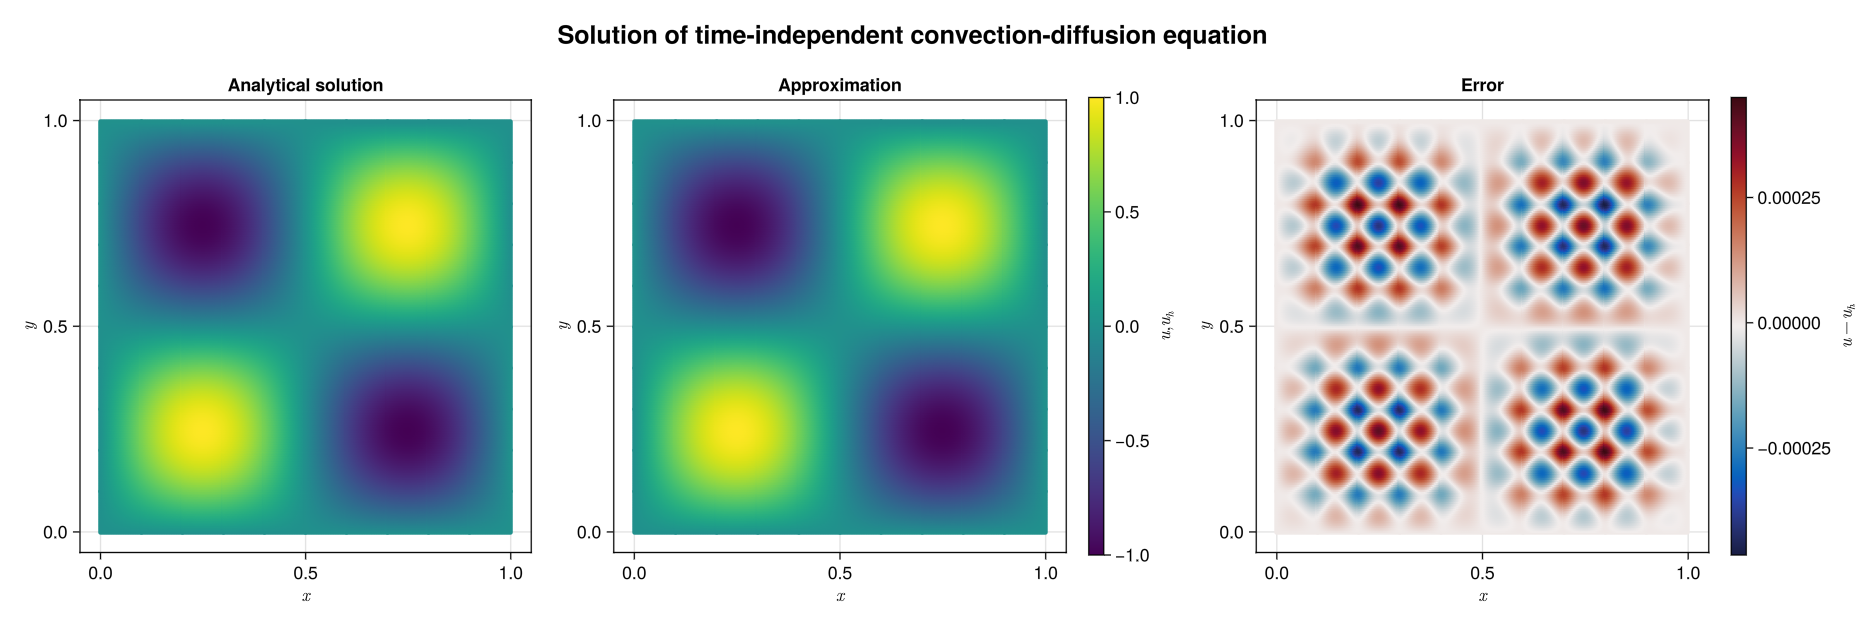

In [4]:
# Solution field for the time-independent problem
u_h = Forms.FormField(V⁰, zeros(Forms.get_num_basis(V⁰)), "u_h")

# Set boundary values
u_h.coefficients[boundary_ids] = U_b

# Solve for the unknown coefficients
u_h.coefficients[interior_ids] = K \ (F - F_b * U_b)

# Compute the L2 norm of the error
error = Analysis.L2_norm(u_analytical - u_h, dΩ)
println("L2 norm of error for time-independent problem: $(error)")

# Helper function to easily evaluate our solution
function evaluate_solution(u_h)
    geometry = Forms.get_geometry(u_h)
    num_elements = Geometry.get_num_elements(geometry)
    xi = Points.TensorProductPoints((LinRange(0.0, 1.0, 25),LinRange(0.0, 1.0, 25)))

    all_x = Vector{Float64}(undef, 25^2 * prod(num_elements))
    all_y = Vector{Float64}(undef, 25^2 * prod(num_elements))
    all_u = Vector{Float64}(undef, 25^2 * prod(num_elements))

    for element_id in 1:prod(num_elements)
        form_eval, _ = Forms.evaluate(u_h, element_id, xi)
        x = Geometry.evaluate(geometry, element_id, xi)

        all_x[((element_id - 1) * 25^2 + 1):((element_id) * 25^2)] = x[:, 1]
        all_y[((element_id - 1) * 25^2 + 1):((element_id) * 25^2)] = x[:, 2]
        all_u[((element_id - 1) * 25^2 + 1):((element_id) * 25^2)] = form_eval[1]
    end

    return all_x, all_y, all_u
end

# Evaluate and plot analytical solution, approximation, and error
xe_analytical, ye_analytical, ue_analytical = evaluate_solution(u_analytical)
xe_h, ye_h, ue_h = evaluate_solution(u_h)
xe_err, ye_err, ue_err = evaluate_solution(u_analytical - u_h)

GLMakie.activate!(inline=true)
fig = Figure(size=(1500, 500))

Label(
    fig[0, 1:5],
    "Solution of time-independent convection-diffusion equation",
    fontsize=20,
    font=:bold,
    tellwidth=false,
    halign=:center
)

ax1 = Axis(
    fig[1, 1],
    title="Analytical solution",
    xlabel=L"x",
    ylabel=L"y",
    aspect=DataAspect()
)

ax2 = Axis(
    fig[1, 2],
    title="Approximation",
    xlabel=L"x",
    ylabel=L"y",
    aspect=DataAspect()
)

col_min = min(minimum(ue_analytical), minimum(ue_h))
col_max = max(maximum(ue_analytical), maximum(ue_h))

p1 = scatter!(
    ax1,
    xe_analytical,
    ye_analytical;
    color=ue_analytical,
    colormap=:viridis,
    colorrange=(col_min, col_max),
    markersize=5
)

p2 = scatter!(
    ax2,
    xe_h,
    ye_h;
    color=ue_h,
    colormap=:viridis,
    colorrange=(col_min, col_max),
    markersize=5
)

Colorbar(fig[1, 3], p1, label=L"u, u_h")

ax3 = Axis(
    fig[1, 4],
    title="Error",
    xlabel=L"x",
    ylabel=L"y",
    aspect=DataAspect()
)

col_min = minimum(ue_err)
col_max = maximum(ue_err)

p3 = scatter!(
    ax3,
    xe_err,
    ye_err;
    color=ue_err,
    colormap=:balance,
    colorrange=(col_min, col_max),
    markersize=5
)

Colorbar(fig[1, 5], p3, label=L"u-u_h")

save("Convection-diffusion_2D.png", fig)
println("Solution of time-independent problem saved as Convection-diffusion_2D.png")
display(fig);

## Solving the time-dependent problem

Finally, we use the explicit midpoint time integration scheme to solve the time-dependent problem given by
$$\mathbf{M} \frac{d\mathbf{C}}{dt} + \mathbf{KC} = \mathbf{F} - \mathbf{F}^b \mathbf{U}^b.$$

In [ ]:
# Time step size
dt = 0.0005

# Number of time steps
num_time_steps = 1001

# Encode the ODE information for the time integrator
import LinearSolve as LS
prob = LS.LinearProblem(M, zeros(size(M, 1)))
linsolve = LS.init(prob)

function convection_diffusion_solver(output, C::Vector{Float64}, t::Float64)
    linsolve.b = (-K * C + F - F_b * U_b)
    output .= LS.solve!(linsolve)
    return output
end
convection_diffusion = TimeIntegrators.define_explicit_ode(convection_diffusion_solver)

# Use explicit midpoint scheme
scheme = TimeIntegrators.EXPLICIT_MIDPOINT

# Project the initial profile onto our form space and enforce the boundary conditions
u_hi = Assemblers.solve_L2_projection(V⁰, g, dΩ)
u_hi.coefficients[boundary_ids] .= U_b

# Initialise the time scheme
u_h_n = TimeIntegrators.initialise_scheme(u_hi.coefficients[interior_ids], scheme)

# Use Printf to print the time in our animation
using Printf
time = Observable(dt)

# Perform time integration
ue_h = lift(time) do t
    TimeIntegrators.time_integrate!(u_h_n, convection_diffusion, t, dt)

    u_hi.coefficients[interior_ids] .= vec(TimeIntegrators.get_solution(u_h_n))

    _, _, all_u = evaluate_solution(u_hi)

    return all_u
end

# Plot analytical solution and approximation
fig = Figure(size=(1000, 500))

Label(
    fig[0, 1:3],
    "Solution of time-dependent convection-diffusion equation",
    fontsize=20,
    font=:bold,
    tellwidth=false,
    halign=:center
)

ax1 = Axis(
    fig[1, 1],
    title="Analytical steady-state solution",
    xlabel=L"x",
    ylabel=L"y",
    aspect=DataAspect()
)

ax2 = Axis(
    fig[1, 2],
    title=@lift("Approximation at t = $(@sprintf("%0.2f", round($time, digits = 2)))"),
    xlabel=L"x",
    ylabel=L"y",
    aspect=DataAspect()
)

col_min = min(minimum(ue_analytical), minimum(ue_h[]))
col_max = max(maximum(ue_analytical), maximum(ue_h[]))

p1 = scatter!(
    ax1,
    xe_analytical,
    ye_analytical;
    color=ue_analytical,
    colormap=:viridis,
    colorrange=(col_min, col_max),
    markersize=5
)

p2 = scatter!(
    ax2,
    xe_h,
    ye_h;
    color=ue_h,
    colormap=:viridis,
    colorrange=(col_min, col_max),
    markersize=5
)

Colorbar(fig[1, 3], p1, label=L"u, u_h")

record(
    fig,
    "Convection-diffusion_2D.mp4",
    LinRange(dt, dt*num_time_steps, num_time_steps);
    framerate=50,
) do t
    return time[] = t
end
println("Solution of time-dependent problem saved as Convection-diffusion_2D.mp4")

using Base64
video_data = base64encode(read("Convection-diffusion_2D.mp4"))
display("text/html", """<video width="1000" controls><source src="data:video/mp4;base64,$video_data" type="video/mp4">Your browser does not support the video tag.</video>""")

Solution of time-dependent problem saved as Convection-diffusion_2D.mp4


Your browser does not support the video tag.